# Resist model and swing curves

The lithography notebooks so far print with a **constant threshold**: the
resist is removed wherever the dose times the image exceeds a threshold,
optionally after a Gaussian blur. Real chemically amplified resists (the
resists of KrF and ArF lithography) get there in steps, and each step leaves
its mark on the printed feature:

| step | model in `pyoptics.litho.resist` | parameters |
|---|---|---|
| image in the resist | `intensity_in_resist(sim)`: $\lvert E\rvert^2$ in an x–z cross section, with standing waves from the `WaferStack` | stack, focus |
| exposure | acid $h_0 = 1 - e^{-C D I}$ (Dill C, no bleaching in DUV) | $C$ [cm²/mJ], dose $D$ [mJ/cm²] |
| post-exposure bake (PEB) | acid diffusion, neutralization by a base quencher, deprotection $\partial_\tau m = -K h m$ | diffusion length $\sigma$, quencher $q_0$, amplification $K$ |
| development | Mack rate $r(m)$ and the development front from $\lvert\nabla T\rvert = 1/r$ (fast marching) | $r_\max$, $r_\min$, $n$, $m_\mathrm{th}$, develop time |
| profile | CD at top, middle and bottom, sidewall angle, top loss | |

Before the chemistry, the optics of the film stack: the light reflected by
the substrate interferes with the incoming light. That gives **standing
waves** through the resist depth and, because the energy coupled into the
resist depends on the thickness, **swing curves**. A bottom anti-reflective
coating (**BARC**) suppresses both; `wafer.swing_curve()` and
`wafer.optimize_barc()` compute them.

Contents:

1. Swing curves: reflectance and absorbed energy through resist thickness.
2. BARC optimization over the angles the illumination actually uses.
3. The image inside the resist, with and without BARC.
4. The resist chain step by step.
5. Standing waves in the profile and how the bake smooths them.
6. CD through dose: full model vs. threshold model, and the quencher.
7. Swing curves of the dose to clear and of the CD.

ArF immersion throughout: 193 nm, water ($n = 1.437$), NA 1.35, 45 nm lines
and spaces with a y-polarized dipole on a 6 % attenuated PSM. All resist
parameters are generic textbook values, not a calibrated resist.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from pyoptics.litho import (Illumination, LithoSimulation, MaskLayout, Projector, ThinMask,
                            WaferStack, resist, wafer)

plt.rcParams.update({"figure.dpi": 100, "font.size": 11})

wl, n_w, NA = 193.0, 1.437, 1.35
RESIST, BARC, SI = (1.70, 0.03), (1.82, 0.34), (0.883, 2.778)  # (n, k) at 193 nm, as in notebook 32
thickness = 100.0

sim = LithoSimulation(MaskLayout.lines_spaces(90.0, 45.0), ThinMask.att_psm(0.06),
                      Illumination.dipole(0.95, 0.7, polarization="y"), Projector(NA, wl, n=n_w))
bare = WaferStack(RESIST + (thickness,), substrate=SI, name="resist on Si")

## 1. Swing curves

A plane wave with transverse wave number $k_0\,\mathrm{na}$ (na runs from 0
at normal incidence up to the NA) enters the stack. `reflectance()` is the
reflectance of the whole stack, `substrate_reflectance()` the reflectance
$|r_b|^2$ of everything below the resist as seen from inside the resist, and
`absorbed()` the fraction of the incident power absorbed in the resist,

$$ A = \frac{k_0\,\mathrm{Im}(n_r^2)}{n_\mathrm{medium}\cos\theta}\int_0^d |E(z)|^2\,dz, $$

integrated analytically (it equals $1 - R - T$ when only the resist absorbs,
which the tests check against `pyoptics.thin_films`). The swing period in
thickness is $\lambda/(2 n_r) \approx 57$ nm at normal incidence; oblique
waves have a longer period.

Which angles matter? The image of the 90 nm pitch is made of the 0th and
the first diffraction orders of each source point, at
$\mathrm{na} = |\mathrm{NA}\,\mathbf s + m\lambda/p\,\hat{\mathbf x}|$.
With the dipole they all lie between na ≈ 0.9 and 1.3: hyper-NA
lithography hits the wafer at steep angles only. The cell below collects
these angles with the source weights (equal weights for the orders, a
simplification) and averages over them.

In [2]:
ill, pitch = sim.illumination, 90.0
na_fill, w_fill = [], []
for m in (-1, 0, 1):
    na = np.hypot(NA*ill.s_x + m*wl/pitch, NA*ill.s_y)
    passed = na <= NA
    na_fill.append(na[passed]); w_fill.append(ill.weights[passed])
na_fill, w_fill = np.concatenate(na_fill), np.concatenate(w_fill)
print(f"{len(na_fill)} plane waves, na from {na_fill.min():.2f} to {na_fill.max():.2f}")

112 plane waves, na from 0.88 to 1.27


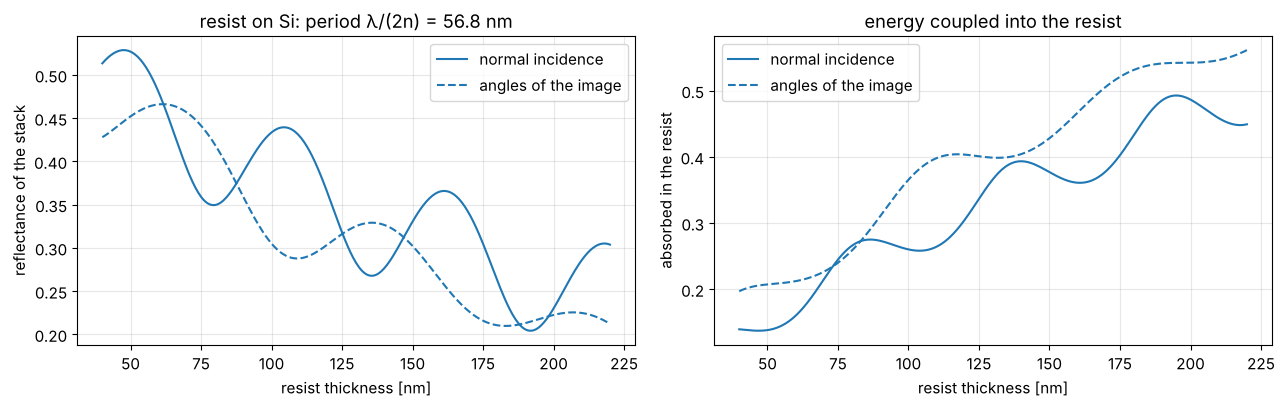

In [3]:
d = np.linspace(40, 220, 361)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for na, w, ls, label in ((0.0, None, "-", "normal incidence"), (na_fill, w_fill, "--", "angles of the image")):
    sc = wafer.swing_curve(bare, d, wl, n_w, na=na, weights=w)
    axes[0].plot(d, sc.reflectance, ls, color="C0", label=label)
    axes[1].plot(d, sc.absorbed, ls, color="C0", label=label)
axes[0].set_ylabel("reflectance of the stack"); axes[1].set_ylabel("absorbed in the resist")
for ax in axes:
    ax.set_xlabel("resist thickness [nm]"); ax.legend(); ax.grid(alpha=0.3)
axes[0].set_title(f"resist on Si: period λ/(2n) = {wl/(2*RESIST[0]):.1f} nm")
axes[1].set_title("energy coupled into the resist")
plt.tight_layout()

The absorbed energy, and with it the dose the resist needs, oscillates by
more than a factor of 1.5 from one thickness to the next quarter period:
on bare silicon a few nanometres of thickness variation over topography
change the CD noticeably.

## 2. BARC optimization

The BARC (here $n = 1.82 + 0.34i$) works by interference and absorption,
so its best thickness depends on the angles. `optimize_barc()` scans the
thickness and minimizes $|r_b|^2$ averaged over the plane waves given. At
NA 1.35 the optimum for normal incidence is not the optimum for the
angles the image is made of, and no single layer reaches zero reflectance
at those steep angles for both TE and TM.

normal incidence: 79.9 nm (|r_b|² = 2.0e-04), angles of the image: 97.7 nm (|r_b|² = 7.1e-03)


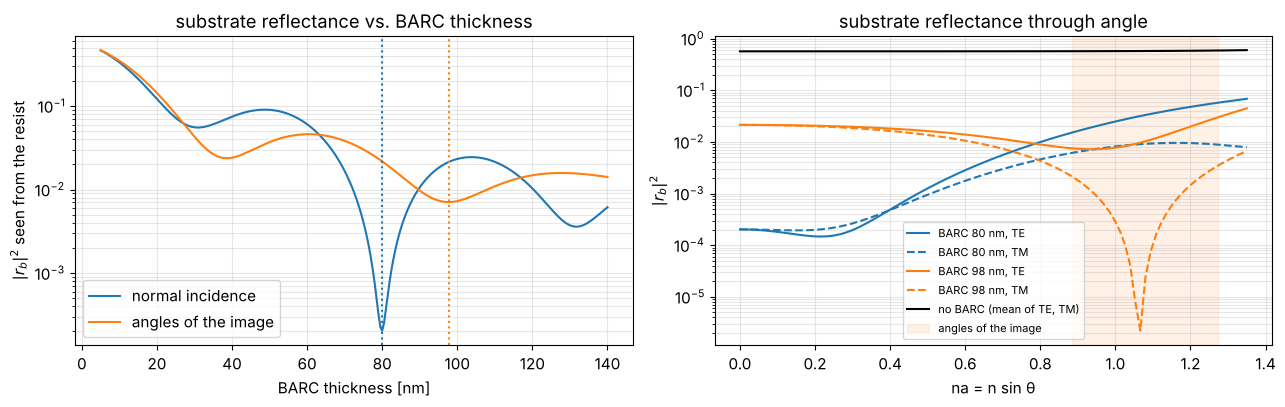

In [4]:
tb = np.linspace(5, 140, 271)
best_0, R_0 = wafer.optimize_barc(bare, BARC, tb, wl, n_w, na=0.0)
best_fill, R_fill = wafer.optimize_barc(bare, BARC, tb, wl, n_w, na=na_fill, weights=w_fill)
print(f"normal incidence: {best_0:.1f} nm (|r_b|² = {R_0.min():.1e}), "
      f"angles of the image: {best_fill:.1f} nm (|r_b|² = {R_fill.min():.1e})")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].plot(tb, R_0, label="normal incidence")
axes[0].plot(tb, R_fill, label="angles of the image")
for b, c in ((best_0, "C0"), (best_fill, "C1")):
    axes[0].axvline(b, color=c, ls=":")
axes[0].set_xlabel("BARC thickness [nm]"); axes[0].set_ylabel("$|r_b|^2$ seen from the resist")
axes[0].set_yscale("log"); axes[0].legend(); axes[0].set_title("substrate reflectance vs. BARC thickness")
na_fine = np.linspace(0, NA, 101)
for b, c in ((best_0, "C0"), (best_fill, "C1")):
    w = bare.with_(below=[BARC + (b,)])
    for pol, ls in (("TE", "-"), ("TM", "--")):
        axes[1].plot(na_fine, w.substrate_reflectance(na_fine, wl, n_w, pol), ls, color=c,
                     label=f"BARC {b:.0f} nm, {pol}")
axes[1].plot(na_fine, bare.substrate_reflectance(na_fine, wl, n_w), color="k", label="no BARC (mean of TE, TM)")
axes[1].axvspan(na_fill.min(), na_fill.max(), color="C1", alpha=0.1, label="angles of the image")
axes[1].set_yscale("log"); axes[1].set_xlabel("na = n sin θ"); axes[1].set_ylabel("$|r_b|^2$")
axes[1].legend(fontsize=8); axes[1].set_title("substrate reflectance through angle")
for ax in axes:
    ax.grid(alpha=0.3, which="both")
plt.tight_layout()

barc = bare.with_(below=[BARC + (best_fill,)], name=f"resist on {best_fill:.0f} nm BARC on Si")

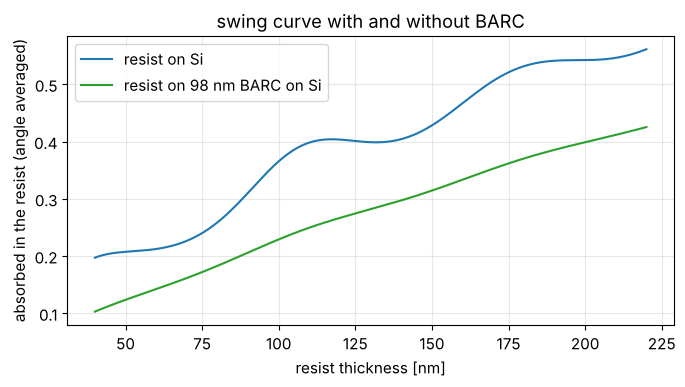

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
for w, c in ((bare, "C0"), (barc, "C2")):
    sc = wafer.swing_curve(w, d, wl, n_w, na=na_fill, weights=w_fill)
    ax.plot(d, sc.absorbed, color=c, label=w.name)
ax.set_xlabel("resist thickness [nm]"); ax.set_ylabel("absorbed in the resist (angle averaged)")
ax.legend(); ax.grid(alpha=0.3); ax.set_title("swing curve with and without BARC")
plt.tight_layout()

With the BARC the absorbed energy rises smoothly with thickness, the Beer
law of the slightly absorbing resist; the swing is nearly gone.

## 3. The image inside the resist

`intensity_in_resist(sim)` computes $|E|^2$ across one period (x, periodic)
and through the resist (z, cell centres), relative to the open frame
intensity incident on the stack. On bare silicon the standing waves
modulate the image through depth almost to zero; with the BARC a weak
modulation from the residual reflectance at these steep angles is left,
on top of the slow absorption decay.

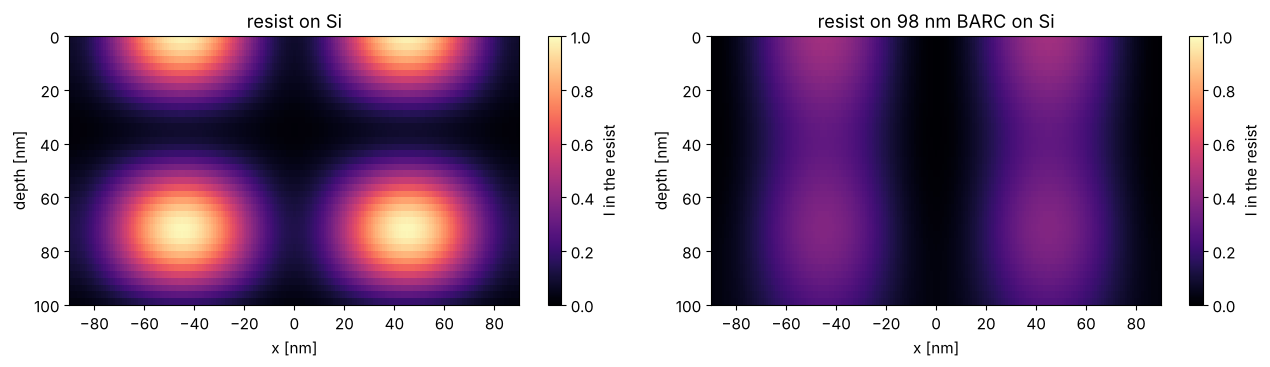

In [6]:
lat_bare = resist.intensity_in_resist(sim.with_(wafer=bare), N_x=96, N_z=40)
lat_barc = resist.intensity_in_resist(sim.with_(wafer=barc), N_x=96, N_z=40)


def periodic(lat, values):
    # three periods of the grid, to show two periods centred on the feature
    x = np.concatenate([lat.x - lat.pitch, lat.x, lat.x + lat.pitch])
    return x, np.concatenate([values]*3, axis=1)


def show_xz(ax, lat, values, **kwargs):
    x, v = periodic(lat, values)
    im = ax.pcolormesh(x, lat.z, v, shading="nearest", **kwargs)
    ax.set_xlim(lat.center - lat.pitch, lat.center + lat.pitch)
    return im


fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, lat, w in zip(axes, (lat_bare, lat_barc), (bare, barc)):
    im = show_xz(ax, lat, lat.I, vmin=0, vmax=1.0, cmap="magma")
    ax.invert_yaxis(); ax.set_xlabel("x [nm]"); ax.set_ylabel("depth [nm]"); ax.set_title(w.name)
    fig.colorbar(im, ax=ax, label="I in the resist")
plt.tight_layout()

## 4. The resist chain step by step

A generic ArF resist: $C = 0.05$ cm²/mJ, acid diffusion length 10 nm,
amplification $K = 2$, quencher 0.1 (relative to the acid generator),
Mack development with $r_\max = 100$ nm/s, $r_\min = 0.1$ nm/s, $n = 5$,
$m_\mathrm{th} = 0.5$ and 60 s develop time. `dose_to_size()` finds the dose
that prints 45 nm at half the resist height.

dose to size: 19.6 mJ/cm²
CD top / middle / bottom: 32.4 / 45.0 / 46.2 nm, sidewall angle 88.5°, top loss 6.0 nm


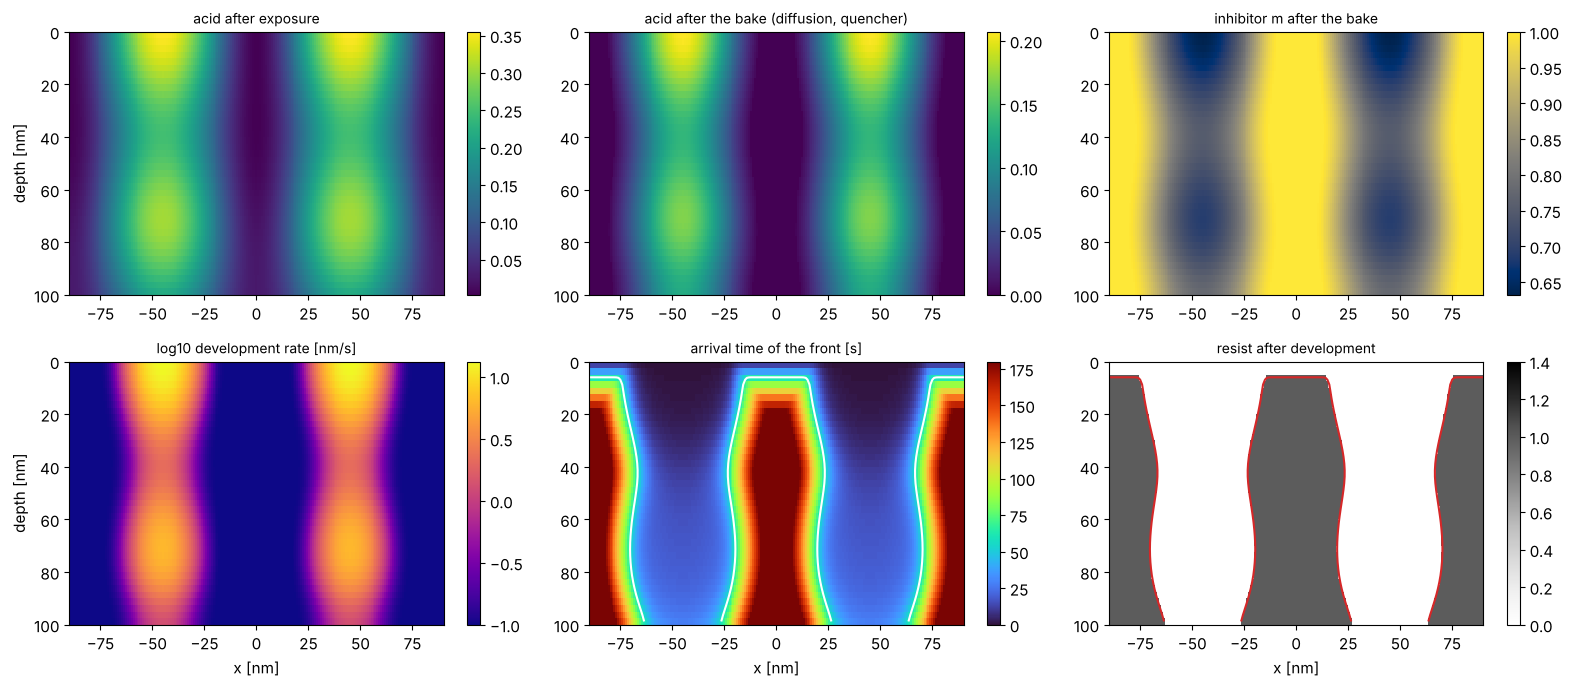

In [7]:
model = resist.ResistModel(C=0.05, diffusion_length=10.0, amplification=2.0, quencher=0.1,
                           r_max=100.0, r_min=0.1, n=5.0, m_th=0.5, develop_time=60.0)
dose = model.dose_to_size(lat_barc, 45.0)
res = model.process(lat_barc, dose)
p = res.profile
print(f"dose to size: {dose:.1f} mJ/cm²")
print(f"CD top / middle / bottom: {p.cd_top:.1f} / {p.cd_middle:.1f} / {p.cd_bottom:.1f} nm, "
      f"sidewall angle {p.sidewall_angle:.1f}°, top loss {p.top_loss:.1f} nm")


def outline(ax, res, **kwargs):
    # the developed profile: contour of the arrival time at the develop time
    x, T = periodic(res.latent, res.arrival)
    kwargs.setdefault("colors", "w")
    ax.contour(x, lat.z, T, levels=[res.develop_time], **kwargs)


fig, axes = plt.subplots(2, 3, figsize=(16, 7))
panels = [(res.acid_0, "acid after exposure", "viridis", None),
          (res.acid, "acid after the bake (diffusion, quencher)", "viridis", None),
          (res.inhibitor, "inhibitor m after the bake", "cividis", None),
          (np.log10(res.rate), "log10 development rate [nm/s]", "plasma", None),
          (res.arrival, "arrival time of the front [s]", "turbo", (0, 3*model.develop_time)),
          (res.resist.astype(float), "resist after development", "Greys", (0, 1.4))]
for ax, (v, title, cmap, lim) in zip(axes.flat, panels):
    im = show_xz(ax, res.latent, v, cmap=cmap, vmin=None if lim is None else lim[0],
                 vmax=None if lim is None else lim[1])
    ax.invert_yaxis(); ax.set_title(title, fontsize=10)
    fig.colorbar(im, ax=ax)
outline(axes[1, 1], res)
outline(axes[1, 2], res, colors="C3")
for ax in axes[1]:
    ax.set_xlabel("x [nm]")
for ax in axes[:, 0]:
    ax.set_ylabel("depth [nm]")
plt.tight_layout()

The quencher removes the acid tail in the dark regions (the bake panel is
zero in the lines), the amplification turns a modest acid contrast into an
inhibitor contrast, and the Mack rate turns that into more than two orders
of magnitude in development rate. The arrival time shows how the front
comes down through the spaces; where it arrives after 60 s, the resist
stays. The lines lose $r_\min \cdot 60\,\mathrm{s} = 6$ nm at the top (top
loss), and their top corners are rounded: the developer works on them
longest.

## 5. Standing waves in the profile

On bare silicon the standing waves are in the acid image as well. The bake
diffuses the acid over $\sigma$; the standing wave period is
$\lambda/(2n_r) = 57$ nm, so a diffusion length of 20 to 30 nm is needed to
flatten them. With a short diffusion length the nodes of the standing wave
develop slowly, and the profile has the typical ridges. Too much diffusion
blurs the image across the 90 nm pitch as well. Each panel is at its own
dose to size.

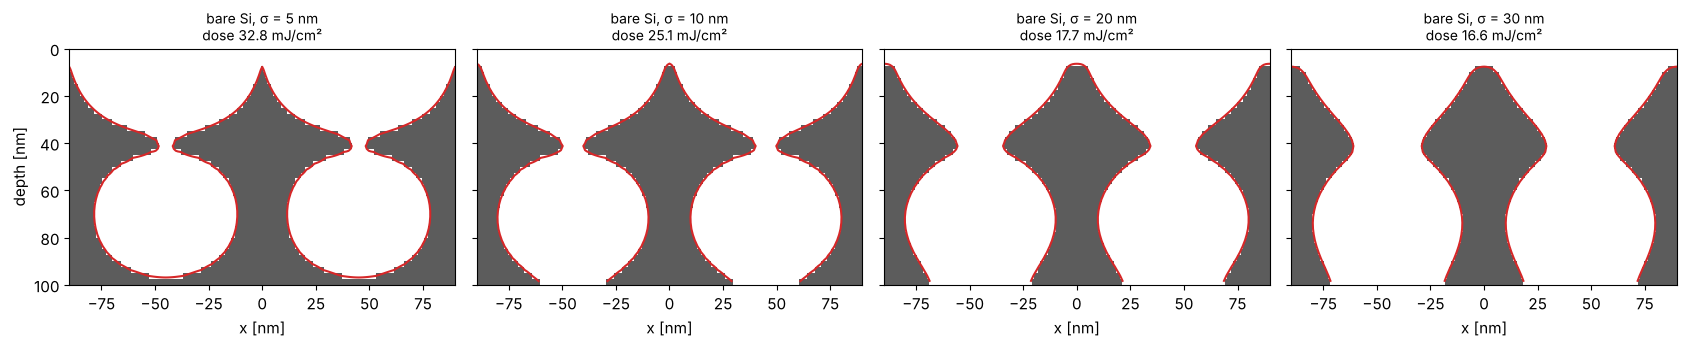

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.6), sharey=True)
for ax, sigma in zip(axes, (5.0, 10.0, 20.0, 30.0)):
    m = model.with_(diffusion_length=sigma)
    D = m.dose_to_size(lat_bare, 45.0)
    note = f"dose {D:.1f} mJ/cm²"
    r = m.process(lat_bare, D)
    show_xz(ax, r.latent, r.resist.astype(float), cmap="Greys", vmin=0, vmax=1.4)
    outline(ax, r, colors="C3")
    ax.set_title(f"bare Si, σ = {sigma:.0f} nm\n{note}", fontsize=10); ax.set_xlabel("x [nm]")
axes[0].set_ylabel("depth [nm]"); axes[0].invert_yaxis()
plt.tight_layout()

## 6. CD through dose

The full chain (with the BARC) against the constant threshold model of the
aerial image, with the threshold chosen so that both print 45 nm at the
nominal dose. Here the resist is more sensitive to dose than the
threshold model: the acid diffusion lowers the image contrast, and the CD
at half height sits at the waist of the profile. More quencher needs more
dose but changes the CD slope little at this diffusion length; it does
reduce the footing (right). Calibrated threshold models absorb such
effects into a fitted blur and threshold, which is why they are fitted to
resist data.

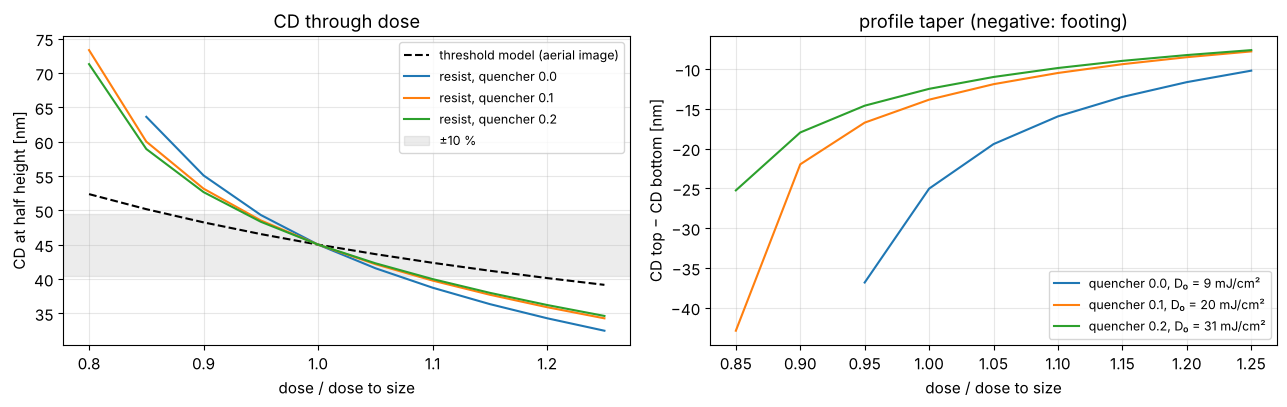

In [9]:
from pyoptics.litho import metrics

doses_rel = np.linspace(0.8, 1.25, 10)
u, I_aerial = sim.cut(N=801)
thr = 1.0/metrics.dose_to_size(u, I_aerial, 45.0, threshold=1.0)  # aerial threshold that prints 45 nm at relative dose 1
cd_thr = [metrics.threshold_cd(u, f*I_aerial, thr) for f in doses_rel]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].plot(doses_rel, cd_thr, "k--", label="threshold model (aerial image)")
for q, c in ((0.0, "C0"), (0.1, "C1"), (0.2, "C2")):
    m = model.with_(quencher=q)
    D0 = m.dose_to_size(lat_barc, 45.0)
    profiles = [m.process(lat_barc, f*D0).profile for f in doses_rel]
    axes[0].plot(doses_rel, [pr.cd_middle for pr in profiles], color=c, label=f"resist, quencher {q}")
    axes[1].plot(doses_rel, [pr.cd_top - pr.cd_bottom for pr in profiles], color=c,
                 label=f"quencher {q}, D₀ = {D0:.0f} mJ/cm²")
axes[0].axhspan(45*0.9, 45*1.1, color="gray", alpha=0.15, label="±10 %")
axes[0].set_xlabel("dose / dose to size"); axes[0].set_ylabel("CD at half height [nm]")
axes[0].legend(fontsize=9); axes[0].set_title("CD through dose")
axes[1].set_xlabel("dose / dose to size"); axes[1].set_ylabel("CD top − CD bottom [nm]")
axes[1].legend(fontsize=9); axes[1].set_title("profile taper (negative: footing)")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()

## 7. Swing curves of the dose

The classic swing curve is the dose to clear $E_0$ of the open frame
through resist thickness: `open_frame_in_resist()` gives the clear-field
intensity through depth and `ResistModel.dose_to_clear()` the dose at
which the development front reaches the bottom within the develop time.
On bare silicon $E_0$ swings, here with the longer period
$\lambda/(2 n_r\cos\theta_r) \approx 75$ nm of the steep dipole poles
($\mathrm{na} \approx 1.1$, $\theta_r \approx 40°$ in the resist) instead of
57 nm at normal incidence. With the BARC it only rises slowly (more resist
to clear, more absorption). The CD
swing at a fixed dose (right) follows: on bare silicon a few nanometres of
thickness change the CD by several nanometres, or the space does not clear
at half height at all (gaps in the curve).

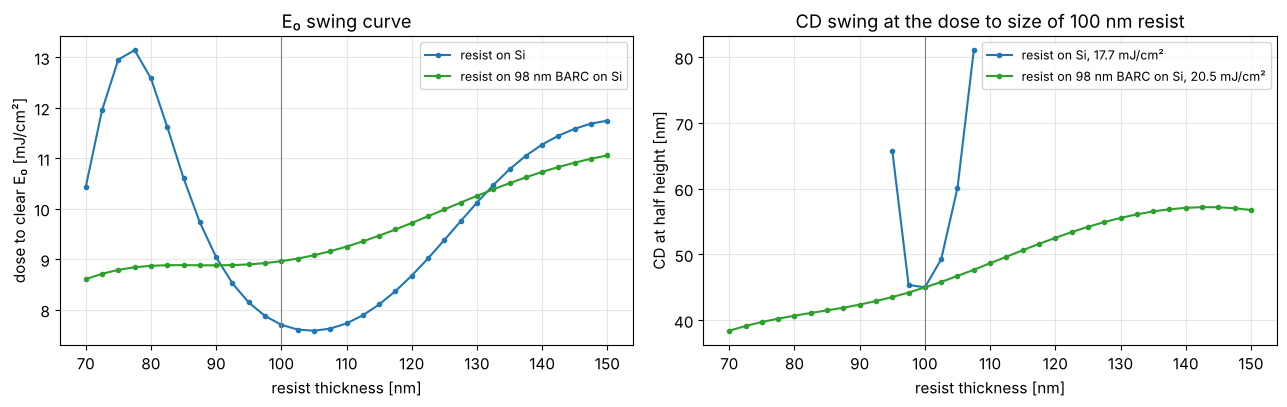

In [10]:
m = model.with_(diffusion_length=20.0)
thick = np.linspace(70, 150, 33)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for w, c in ((bare, "C0"), (barc, "C2")):
    E_0 = [m.dose_to_clear(resist.open_frame_in_resist(sim.with_(wafer=w.with_(thickness=t))))
           for t in thick]
    axes[0].plot(thick, E_0, "o-", ms=3, color=c, label=w.name)
    D = m.dose_to_size(resist.intensity_in_resist(sim.with_(wafer=w), N_x=96, N_z=40), 45.0)
    cds = [m.process(resist.intensity_in_resist(sim.with_(wafer=w.with_(thickness=t)), N_x=96, N_z=40), D)
           .profile.cd_middle for t in thick]
    axes[1].plot(thick, cds, "o-", ms=3, color=c, label=f"{w.name}, {D:.1f} mJ/cm²")
axes[0].set_ylabel("dose to clear E₀ [mJ/cm²]"); axes[0].set_title("E₀ swing curve")
axes[1].set_ylabel("CD at half height [nm]"); axes[1].set_title("CD swing at the dose to size of 100 nm resist")
for ax in axes:
    ax.axvline(thickness, color="gray", lw=0.8)
    ax.set_xlabel("resist thickness [nm]"); ax.legend(fontsize=9); ax.grid(alpha=0.3)
plt.tight_layout()

## Summary

- `wafer.swing_curve()` gives reflectance, absorbed energy and substrate
  reflectance through resist thickness, averaged over the illumination
  angles; the swing period is $\lambda/(2n_r)$.
- `wafer.optimize_barc()` picks the BARC thickness for the angles that
  matter: at NA 1.35 it differs from the normal incidence optimum.
- `resist.intensity_in_resist()` gives the image inside the resist, with
  the standing waves; `resist.ResistModel` runs exposure, PEB (diffusion,
  quencher, amplification) and Mack development with a fast marching
  development front, and reports CD at top, middle and bottom, sidewall
  angle and top loss.
- `ResistModel.dose_to_clear()` on `open_frame_in_resist()` gives the
  classic $E_0$ swing curve; `dose_to_size()` the dose for a CD at any
  height of the profile.
- The bake smooths the standing waves once the diffusion length reaches
  about a third to a half of their period, at the price of image contrast
  across the pitch.
- Limitations: an x–z cross section (no diffusion along the lines), no
  bleaching, a generic uncalibrated resist, and fixed optical constants
  during exposure.